# Part B — Customer Segments and Lapse Prediction

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate project folder
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Load Part A cleaned datasets
customers = pd.read_csv(BASE_DIR / "data/clean/Customer_data_Cleaned.csv")
orders = pd.read_csv(BASE_DIR / "data/clean/Order_details_cleaned.csv")

# Check datasets
print("Customers shape:", customers.shape)
print("Orders shape:", orders.shape)

print("\nCustomer columns:")
print(customers.columns.tolist())

print("\nOrder columns:")
print(orders.columns.tolist())

print("\nOrder data types:")
print(orders.dtypes)

print("\nOrder timestamp examples:")
print(orders["order_ts"].head())

Customers shape: (1200, 5)
Orders shape: (12305, 10)

Customer columns:
['customer_id', 'city', 'signup_date', 'age', 'gender']

Order columns:
['order_id', 'customer_id', 'product_id', 'quantity', 'order_ts', 'status', 'discount_pct', 'order_amount', 'delivery_minutes', 'price_inr']

Order data types:
order_id             object
customer_id          object
product_id           object
quantity              int64
order_ts             object
status               object
discount_pct          int64
order_amount        float64
delivery_minutes    float64
price_inr             int64
dtype: object

Order timestamp examples:
0    2025-04-01 07:08:28
1    2025-04-01 07:11:59
2    2025-04-01 07:12:43
3    2025-04-01 07:54:43
4    2025-04-01 08:02:58
Name: order_ts, dtype: object


In [3]:
# Check customer dataset
print("CUSTOMER DATA")
display(customers.head())

print("\nCustomer columns:")
print(customers.columns.tolist())


# Check order dataset
print("\nORDER DATA")
display(orders.head())

print("\nOrder columns:")
print(orders.columns.tolist())


# Check order data types
print("\nOrder data types:")
print(orders.dtypes)


# Check order status
print("\nOrder status counts:")
print(orders["status"].value_counts())

CUSTOMER DATA


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35,Male
1,C0002,Delhi,2024-02-17,31,Male
2,C0003,Bengaluru,2025-02-18,18,Female
3,C0004,Bengaluru,2024-06-21,24,Female
4,C0005,Bengaluru,2024-10-01,25,Female



Customer columns:
['customer_id', 'city', 'signup_date', 'age', 'gender']

ORDER DATA


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes,price_inr
0,ORD-110093,C0967,P020,1,2025-04-01 07:08:28,completed,15,127.50,19.0,150
1,ORD-111396,C1117,P036,2,2025-04-01 07:11:59,completed,0,1598.00,25.0,799
2,ORD-102006,C0194,P009,1,2025-04-01 07:12:43,cancelled,25,21.75,NaN,29
3,ORD-105921,C0569,P005,2,2025-04-01 07:54:43,completed,10,86.40,33.0,48
4,ORD-108115,C0776,P012,2,2025-04-01 08:02:58,completed,10,104.40,21.0,58



Order columns:
['order_id', 'customer_id', 'product_id', 'quantity', 'order_ts', 'status', 'discount_pct', 'order_amount', 'delivery_minutes', 'price_inr']

Order data types:
order_id             object
customer_id          object
product_id           object
quantity              int64
order_ts             object
status               object
discount_pct          int64
order_amount        float64
delivery_minutes    float64
price_inr             int64
dtype: object

Order status counts:
status
completed    11106
cancelled     1199
Name: count, dtype: int64


# Use only completed orders for customer behaviour unless a task says otherwise.

# 1. Build the RFM table

1. R _ recency = whole days between the snapshot and the customer's most recent completed order ((snapshot − last_order_ts).dt.days);
2. F _ frequency = number of distinct completed orders;
3. M _ monetary = sum of completed order_amount.

   Reference:  1,175 customers;
               recency median 19,
               minimum 0,
               maximum 180;
               frequency mean 9.46,
               maximum 33;
               monetary mean 2,552.06,
               maximum 14,766.55.

In [4]:
orders.head()

,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes,price_inr
0,ORD-110093,C0967,P020,1,2025-04-01 07:08:28,completed,15,127.50,19.0,150
1,ORD-111396,C1117,P036,2,2025-04-01 07:11:59,completed,0,1598.00,25.0,799
2,ORD-102006,C0194,P009,1,2025-04-01 07:12:43,cancelled,25,21.75,NaN,29
3,ORD-105921,C0569,P005,2,2025-04-01 07:54:43,completed,10,86.40,33.0,48
4,ORD-108115,C0776,P012,2,2025-04-01 08:02:58,completed,10,104.40,21.0,58


In [5]:
order_rfm = orders.copy()

In [6]:
order_rfm.dtypes

order_id             object
customer_id          object
product_id           object
quantity              int64
order_ts             object
status               object
discount_pct          int64
order_amount        float64
delivery_minutes    float64
price_inr             int64
dtype: object

In [7]:
order_rfm["order_ts"]= pd.to_datetime(order_rfm["order_ts"], errors = "coerce")

In [8]:
order_rfm.dtypes

order_id                    object
customer_id                 object
product_id                  object
quantity                     int64
order_ts            datetime64[ns]
status                      object
discount_pct                 int64
order_amount               float64
delivery_minutes           float64
price_inr                    int64
dtype: object

In [9]:
# Check invalid dates
print("1. Invalid dates:", order_rfm["order_ts"].isna().sum())

# Filter only completed orders
completed_orders = order_rfm[
    order_rfm["status"] == "completed"
].copy()

# Check results
print("2. Completed orders:", len(completed_orders))

print("\n 3. Completed order sample:")
display(completed_orders.head())

1. Invalid dates: 0
2. Completed orders: 11106

 3. Completed order sample:


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes,price_inr
0,ORD-110093,C0967,P020,1,2025-04-01 07:08:28,completed,15,127.5,19.0,150
1,ORD-111396,C1117,P036,2,2025-04-01 07:11:59,completed,0,1598.0,25.0,799
3,ORD-105921,C0569,P005,2,2025-04-01 07:54:43,completed,10,86.4,33.0,48
4,ORD-108115,C0776,P012,2,2025-04-01 08:02:58,completed,10,104.4,21.0,58
5,ORD-111469,C1122,P017,3,2025-04-01 08:26:52,completed,25,45.0,72.0,20


## RFM of the completed order

1. Rfm_table the table contain only customer id, recency,frquency,monetary. 

In [10]:
# Snapshot date
snapshot_date = pd.Timestamp("2025-10-01 00:00:00")

# Group completed orders by customer
rfm = completed_orders.groupby("customer_id").agg(
    last_order_ts=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_amount", "sum")
).reset_index()

# Calculate recency
rfm["recency"] = (
    snapshot_date - rfm["last_order_ts"]
).dt.days

# Remove intermediate date column
rfm = rfm.drop(columns=["last_order_ts"])

# Arrange columns
rfm = rfm[
    ["customer_id", "recency", "frequency", "monetary"]
]

# Display RFM table
display(rfm.head(10))

print("\nRFM table shape:", rfm.shape)

,customer_id,recency,frequency,monetary
0,C0001,14,4,512.85
1,C0002,28,7,4644.90
2,C0003,7,22,3644.85
3,C0004,0,5,369.00
4,C0005,147,2,324.00
5,C0006,34,1,90.00
6,C0007,3,18,2600.00
7,C0008,3,15,3096.50
8,C0009,19,11,8424.80
9,C0010,66,4,450.00



RFM table shape: (1175, 4)


In [11]:
print("Total customers:", len(rfm))

print("\nRecency:")
print(rfm["recency"].describe())

print("\nFrequency:")
print(rfm["frequency"].describe())

print("\nMonetary:")
print(rfm["monetary"].describe())

Total customers: 1175

Recency:
count    1175.000000
mean       33.558298
std        38.433705
min         0.000000
25%         6.000000
50%        19.000000
75%        46.000000
max       180.000000
Name: recency, dtype: float64

Frequency:
count    1175.000000
mean        9.451915
std         8.008675
min         1.000000
25%         3.000000
50%         5.000000
75%        17.000000
max        33.000000
Name: frequency, dtype: float64

Monetary:
count     1175.000000
mean      2549.499745
std       2366.507739
min         12.000000
25%        505.450000
50%       2282.200000
75%       3749.650000
max      14766.550000
Name: monetary, dtype: float64


In [12]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from sklearn.preprocessing import StandardScaler

# Select RFM features
rfm_features = rfm[
    ["recency", "frequency", "monetary"]
]

# Create scaler
scaler = StandardScaler()

# Standardise RFM data
rfm_scaled = scaler.fit_transform(rfm_features)

print("Original RFM shape:", rfm_features.shape)
print("Scaled RFM shape:", rfm_scaled.shape)

print("\nFirst 5 scaled rows:")
print(rfm_scaled[:5])

Original RFM shape: (1175, 3)
Scaled RFM shape: (1175, 3)

First 5 scaled rows:
[[-0.50910069 -0.68104107 -0.86098048]
 [-0.14468198 -0.30628775  0.88581687]
 [-0.69131004  1.56747885  0.46305222]
 [-0.8735194  -0.55612329 -0.92179213]
 [ 2.95287704 -0.93087661 -0.94081559]]


In [14]:
rfm_scaled

array([[-0.50910069, -0.68104107, -0.86098048],
       [-0.14468198, -0.30628775,  0.88581687],
       [-0.69131004,  1.56747885,  0.46305222],
       ...,
       [-0.79542967,  1.06780776,  0.10725014],
       [-0.45704087, -0.68104107,  0.55478756],
       [-0.82145958,  1.56747885,  0.42680196]], shape=(1175, 3))

In [15]:
rfm

,customer_id,recency,frequency,monetary
0,C0001,14,4,512.85
1,C0002,28,7,4644.90
2,C0003,7,22,3644.85
3,C0004,0,5,369.00
4,C0005,147,2,324.00
...,...,...,...,...
1170,C1196,104,3,339.00
1171,C1197,4,23,3397.15
1172,C1198,3,18,2803.20
1173,C1199,16,4,3861.85


# 2. Cluster with K-means (5 marks). 

**Description.**

Standardise the three RFM columns with StandardScaler. For every K from 2 to 8 fit KMeans(n_clusters=K, n_init=10, random_state=42) and record the inertia and the silhouette score. Present the table, read the elbow, and choose the final K from {3, 4, 5} using the elbow, the silhouette scores and business interpretability (a number that the business can act on beats a marginally better metric). Reference (tolerance ±5% on inertia, ±0.05 on silhouette): K=2: 1820.8 / 0.465; K=3: 1268.2 / 0.445; K=4: 743.1 / 0.526; K=5: 617.4 / 0.481; K=6: 503.2 / 0.482; K=7: 408.5 / 0.416; K=8: 366.5 / 0.412. Explain in two or three sentences why the inertia of K=8 is always lower than that of K=2 yet that fact alone cannot pick K.

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store clustering results
kmeans_results = []

# Test K from 2 to 8
for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled)

    inertia = kmeans.inertia_

    silhouette = silhouette_score(
        rfm_scaled,
        cluster_labels
    )

    kmeans_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })

# Convert results into DataFrame
kmeans_table = pd.DataFrame(kmeans_results)

display(kmeans_table.round(3))

,K,Inertia,Silhouette Score
0,2,1820.283,0.466
1,3,1267.207,0.446
2,4,741.899,0.526
3,5,616.296,0.481
4,6,502.747,0.483
5,7,408.056,0.417
6,8,365.894,0.412


In [21]:
%pip install matplotlib

     ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/8.2 MB 217.9 kB/s eta 0:00:38
     ---------------------------------------- 0.0/8.2 MB 326.8 kB/s eta 0:00:25
     ---------------------------------------- 0.1/8.2 MB 469.7 kB/s eta 0:00:18
     ---------------------------------------- 0.1/8.2 MB 535.8 kB/s eta 0:00:16
      --------------------------------------- 0.2/8.2 MB 762.6 kB/s eta 0:00:11
      --------------------------------------- 0.2/8.2 MB 655.4 kB/s eta 0:00:13
     - -------------------------------------- 0.2/8.2 MB 801.7 kB/s eta 0:00:10
     - -------------------------------------- 0.3/8.2 MB 780.5 kB/s eta 0:00:11
     - -------------------------------------- 0.3/8.2 MB 912.8 kB/s eta 0:00:09
     -- ------------------------------------- 0.4/8.2 MB 1.0 MB/s eta 0:00:08
     -- ------------------------------------- 0.5/8.2 MB 1.0


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


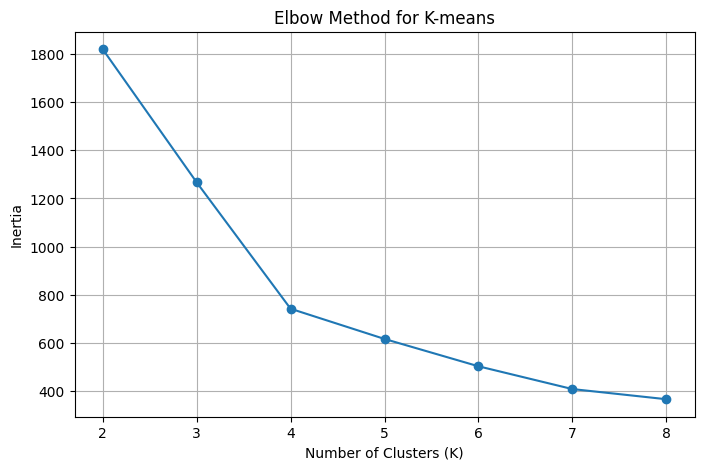

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_table["K"],
    kmeans_table["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means")

plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

# 3. Profile, name and project the segments (3 marks).

In [23]:
from sklearn.cluster import KMeans

# Select final number of clusters
final_k = 4

# Train final K-means model
final_kmeans = KMeans(
    n_clusters=final_k,
    n_init=10,
    random_state=42
)

# Assign cluster labels
rfm["segment_id"] = final_kmeans.fit_predict(rfm_scaled)

# Check cluster counts
print("Customer count in each segment:")
print(rfm["segment_id"].value_counts().sort_index())

Customer count in each segment:
segment_id
0    436
1    138
2    419
3    182
Name: count, dtype: int64


In [24]:
# Calculate segment profiles
segment_profile = rfm.groupby("segment_id").agg(
    customer_count=("customer_id", "count"),
    mean_recency=("recency", "mean"),
    mean_frequency=("frequency", "mean"),
    mean_monetary=("monetary", "mean")
).round(2)

display(segment_profile)

,customer_count,mean_recency,mean_frequency,mean_monetary
segment_id,,,,
0,436,28.86,3.77,1052.12
1,138,24.12,6.76,7127.10
2,419,8.77,19.40,3409.43
3,182,109.04,2.20,685.99


In [25]:
# Find segment with highest mean monetary value
premium_segment = segment_profile["mean_monetary"].idxmax()

print("Premium segment ID:", premium_segment)

print(
    "Premium segment mean monetary:",
    segment_profile.loc[premium_segment, "mean_monetary"]
)

Premium segment ID: 1
Premium segment mean monetary: 7127.1


In [26]:
from sklearn.decomposition import PCA

# Apply PCA to scaled RFM data
pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

# Explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal explained variance:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.6342838  0.21810572]

Total explained variance:
0.852389513203515


In [31]:
rfm_scaled

array([[-0.50910069, -0.68104107, -0.86098048],
       [-0.14468198, -0.30628775,  0.88581687],
       [-0.69131004,  1.56747885,  0.46305222],
       ...,
       [-0.79542967,  1.06780776,  0.10725014],
       [-0.45704087, -0.68104107,  0.55478756],
       [-0.82145958,  1.56747885,  0.42680196]], shape=(1175, 3))

In [27]:
rfm_pca

array([[-0.58089102, -0.84629985],
       [ 0.36929263,  0.70486273],
       [ 1.61091876, -0.30375882],
       ...,
       [ 1.17516895, -0.55311136],
       [ 0.144606  ,  0.33826302],
       [ 1.66733713, -0.40401517]], shape=(1175, 2))

In [28]:
rfm

,customer_id,recency,frequency,monetary,segment_id
0,C0001,14,4,512.85,0
1,C0002,28,7,4644.90,1
2,C0003,7,22,3644.85,2
3,C0004,0,5,369.00,0
4,C0005,147,2,324.00,3
...,...,...,...,...,...
1170,C1196,104,3,339.00,3
1171,C1197,4,23,3397.15,2
1172,C1198,3,18,2803.20,2
1173,C1199,16,4,3861.85,0


In [29]:
segment_profile

,customer_count,mean_recency,mean_frequency,mean_monetary
segment_id,,,,
0,436,28.86,3.77,1052.12
1,138,24.12,6.76,7127.10
2,419,8.77,19.40,3409.43
3,182,109.04,2.20,685.99


## 3.2. Save a customer segments as CSV file

In [32]:
# Assign business names to segments
segment_names = {
    0: "Occasional Customers",
    1: "Premium High-Spending Customers",
    2: "Frequent Loyal Customers",
    3: "Dormant At-Risk Customers"
}

# Add segment names
rfm["segment_name"] = rfm["segment_id"].map(segment_names)

# Identify Premium segment
rfm["is_premium"] = rfm["segment_id"] == premium_segment

# Display results
display(rfm.head(10))

,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,Occasional Customers,False
1,C0002,28,7,4644.90,1,Premium High-Spending Customers,True
2,C0003,7,22,3644.85,2,Frequent Loyal Customers,False
3,C0004,0,5,369.00,0,Occasional Customers,False
4,C0005,147,2,324.00,3,Dormant At-Risk Customers,False
5,C0006,34,1,90.00,0,Occasional Customers,False
6,C0007,3,18,2600.00,2,Frequent Loyal Customers,False
7,C0008,3,15,3096.50,2,Frequent Loyal Customers,False
8,C0009,19,11,8424.80,1,Premium High-Spending Customers,True
9,C0010,66,4,450.00,0,Occasional Customers,False


In [36]:
# Select required columns
customer_segments = rfm[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "segment_id",
        "segment_name",
        "is_premium"
    ]
].copy()


In [33]:
from pathlib import Path

OUTPUT_DIR = BASE_DIR / "outputs"

In [34]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [38]:
customer_segments.to_csv(
    OUTPUT_DIR / "customer_segments.csv",
    index=False
)

print("Customer segments file created successfully!")

Customer segments file created successfully!


In [39]:
# Verify output
print("\nFile location:")
print(OUTPUT_DIR / "customer_segments.csv")

print("\nOutput shape:", customer_segments.shape)

display(customer_segments.head(10))


File location:
C:\Users\PRAVEEN_KUMAR\jupyter_notebook\Jupyter notebook\Masai_Code\outputs\customer_segments.csv

Output shape: (1175, 7)


,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,Occasional Customers,False
1,C0002,28,7,4644.90,1,Premium High-Spending Customers,True
2,C0003,7,22,3644.85,2,Frequent Loyal Customers,False
3,C0004,0,5,369.00,0,Occasional Customers,False
4,C0005,147,2,324.00,3,Dormant At-Risk Customers,False
5,C0006,34,1,90.00,0,Occasional Customers,False
6,C0007,3,18,2600.00,2,Frequent Loyal Customers,False
7,C0008,3,15,3096.50,2,Frequent Loyal Customers,False
8,C0009,19,11,8424.80,1,Premium High-Spending Customers,True
9,C0010,66,4,450.00,0,Occasional Customers,False


In [40]:
print(BASE_DIR)

C:\Users\PRAVEEN_KUMAR\jupyter_notebook\Jupyter notebook\Masai_Code


In [41]:
# Read the saved file
check_segments = pd.read_csv(
    OUTPUT_DIR / "customer_segments.csv"
)

print("Total customers:", len(check_segments))

print("\nSegment distribution:")
print(check_segments["segment_name"].value_counts())

print("\nPremium customer count:")
print(check_segments["is_premium"].sum())

print("\nColumn names:")
print(check_segments.columns.tolist())

Total customers: 1175

Segment distribution:
segment_name
Occasional Customers               436
Frequent Loyal Customers           419
Dormant At-Risk Customers          182
Premium High-Spending Customers    138
Name: count, dtype: int64

Premium customer count:
138

Column names:
['customer_id', 'recency', 'frequency', 'monetary', 'segment_id', 'segment_name', 'is_premium']


# 4. Define the lapse problem'

In [42]:
# Display available cleaned CSV files
clean_files = list((BASE_DIR / "data/clean").glob("*.csv"))

for file in clean_files:
    print(file.name)

Customer_data_Cleaned.csv
Order_details_cleaned.csv
Product_Cleaned.csv


In [43]:
# Load cleaned product dataset
products = pd.read_csv(
    BASE_DIR / "data/clean/Product_Cleaned.csv"
)

# Inspect product data
print("Products shape:", products.shape)

print("\nProduct columns:")
print(products.columns.tolist())

display(products.head())

Products shape: (40, 4)

Product columns:
['product_id', 'product_name', 'category', 'price_inr']


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245
3,P004,Sunflower Oil 1L,Grocery,155
4,P005,Sugar 1kg,Grocery,48


In [44]:
# Create a copy of orders
orders_lapse = orders.copy()

# Convert order timestamp into datetime
orders_lapse["order_ts"] = pd.to_datetime(
    orders_lapse["order_ts"],
    errors="coerce"
)

# Check invalid dates
print("Invalid timestamps:", orders_lapse["order_ts"].isna().sum())

Invalid timestamps: 0


In [45]:
# Define cutoff date
cutoff_date = pd.Timestamp("2025-09-01 00:00:00")

# Define September observation period
observation_end = pd.Timestamp("2025-10-01 00:00:00")

print("Cutoff date:", cutoff_date)
print("Observation period:", cutoff_date, "to", observation_end)

Cutoff date: 2025-09-01 00:00:00
Observation period: 2025-09-01 00:00:00 to 2025-10-01 00:00:00


In [46]:
# Filter orders before cutoff
historical_orders = orders_lapse[
    orders_lapse["order_ts"] < cutoff_date
].copy()

# Check completed historical orders
historical_completed = historical_orders[
    historical_orders["status"] == "completed"
].copy()

print("Total historical orders:", len(historical_orders))

print(
    "Completed historical orders:",
    len(historical_completed)
)

Total historical orders: 10298
Completed historical orders: 9278


In [47]:
# Filter September orders
september_orders = orders_lapse[
    (orders_lapse["order_ts"] >= cutoff_date) &
    (orders_lapse["order_ts"] < observation_end)
].copy()

# Keep completed September orders
september_completed = september_orders[
    september_orders["status"] == "completed"
].copy()

print("Total September orders:", len(september_orders))

print(
    "Completed September orders:",
    len(september_completed)
)

Total September orders: 2007
Completed September orders: 1828


In [48]:
# Identify customers with historical completed orders
cohort_customer_ids = historical_completed[
    "customer_id"
].unique()

# Create customer cohort
cohort = customers[
    customers["customer_id"].isin(cohort_customer_ids)
].copy()

print("Total customers in cohort:", len(cohort))

Total customers in cohort: 1156


In [49]:
# Identify customers who completed an order in September
september_customer_ids = set(
    september_completed["customer_id"].unique()
)

# Create lapse target
cohort["lapsed"] = (
    ~cohort["customer_id"].isin(september_customer_ids)
).astype(int)

# Check label distribution
print("Lapse label distribution:")
print(cohort["lapsed"].value_counts())

print("\nLapse percentage:")
print(
    round(cohort["lapsed"].mean() * 100, 2),
    "%"
)

Lapse label distribution:
lapsed
0    713
1    443
Name: count, dtype: int64

Lapse percentage:
38.32 %


## 4.1. Calculate RFM features
We already calculated RFM in Task 1, but that RFM used the entire order history.

For lapse prediction, we must calculate RFM again using only historical completed orders.

In [50]:
# Group historical completed orders by customer
customer_features = historical_completed.groupby("customer_id").agg(

    # Most recent completed order
    last_order_ts=("order_ts", "max"),

    # Number of distinct completed orders
    frequency=("order_id", "nunique"),

    # Total spending
    monetary=("order_amount", "sum"),

    # Average discount
    avg_discount=("discount_pct", "mean"),

    # Average delivery time
    avg_delivery_minutes=("delivery_minutes", "mean")

).reset_index()

# Calculate recency using the cutoff date
customer_features["recency"] = (
    cutoff_date - customer_features["last_order_ts"]
).dt.days

# Remove intermediate date column
customer_features = customer_features.drop(
    columns=["last_order_ts"]
)

# Check results
display(customer_features.head())

print("Feature dataset shape:", customer_features.shape)

,customer_id,frequency,monetary,avg_discount,avg_delivery_minutes,recency
0,C0001,2,378.00,10.000000,28.000000,33
1,C0002,6,3946.90,6.666667,21.916667,22
2,C0003,20,3264.05,12.750000,24.200000,1
3,C0004,3,272.25,11.666667,35.666667,42
4,C0005,2,324.00,25.000000,26.000000,117


Feature dataset shape: (1156, 6)


In [55]:
# Select orders with a final status
final_status_orders = historical_orders[
    historical_orders["status"].isin(
        ["completed", "cancelled"]
    )
].copy()

# Count total and cancelled orders per customer
cancellation_features = final_status_orders.groupby(
    "customer_id"
).agg(
    total_final_orders=("order_id", "nunique"),
    cancelled_orders=(
        "status",
        lambda x: (x == "cancelled").sum()
    )
).reset_index()

# Calculate cancellation rate
cancellation_features["cancellation_rate"] = (
    cancellation_features["cancelled_orders"] /
    cancellation_features["total_final_orders"]
)

# Keep required columns
cancellation_features = cancellation_features[
    ["customer_id", "cancellation_rate"]
]

display(cancellation_features.head())

,customer_id,cancellation_rate
0,C0001,0.000000
1,C0002,0.000000
2,C0003,0.000000
3,C0004,0.400000
4,C0005,0.333333


In [51]:
print(products.columns.tolist())

['product_id', 'product_name', 'category', 'price_inr']


In [56]:
# Connect historical completed orders with products
category_orders = historical_completed.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Count purchases in each category for each customer
category_counts = category_orders.groupby(
    ["customer_id", "category"]
).size().reset_index(name="category_count")

# Sort by highest purchase count
category_counts = category_counts.sort_values(
    ["customer_id", "category_count", "category"],
    ascending=[True, False, True]
)

# Select the most frequently purchased category
favourite_category = category_counts.drop_duplicates(
    subset="customer_id"
)[["customer_id", "category"]]

# Rename category column
favourite_category = favourite_category.rename(
    columns={"category": "favourite_category"}
)

display(favourite_category.head())

,customer_id,favourite_category
0,C0001,Grocery
2,C0002,Electronics
6,C0003,Grocery
9,C0004,Snacks
10,C0005,Dairy


In [57]:
# Select customer demographic information
customer_demographics = cohort[
    [
        "customer_id",
        "city",
        "age",
        "gender",
        "signup_date",
        "lapsed"
    ]
].copy()

# Convert signup_date into datetime
customer_demographics["signup_date"] = pd.to_datetime(
    customer_demographics["signup_date"],
    errors="coerce"
)

# Calculate customer tenure
customer_demographics["tenure_days"] = (
    cutoff_date - customer_demographics["signup_date"]
).dt.days

# Remove signup_date because tenure is our required feature
customer_demographics = customer_demographics.drop(
    columns=["signup_date"]
)

display(customer_demographics.head())

,customer_id,city,age,gender,lapsed,tenure_days
0,C0001,Chennai,35,Male,0,597
1,C0002,Delhi,31,Male,0,562
2,C0003,Bengaluru,18,Female,0,195
3,C0004,Bengaluru,24,Female,0,437
4,C0005,Bengaluru,25,Female,1,335


In [58]:
# Merge customer RFM and behaviour features
lapse_features = customer_features.merge(
    cancellation_features,
    on="customer_id",
    how="left"
)

# Add favourite product category
lapse_features = lapse_features.merge(
    favourite_category,
    on="customer_id",
    how="left"
)

# Add customer demographic information and target
lapse_features = lapse_features.merge(
    customer_demographics,
    on="customer_id",
    how="inner"
)

# Check final dataset
print("Final lapse dataset shape:", lapse_features.shape)

display(lapse_features.head(10))

print("\nFinal columns:")
print(lapse_features.columns.tolist())

Final lapse dataset shape: (1156, 13)


,customer_id,frequency,monetary,avg_discount,avg_delivery_minutes,recency,cancellation_rate,favourite_category,city,age,gender,lapsed,tenure_days
0,C0001,2,378.00,10.000000,28.000000,33,0.000000,Grocery,Chennai,35,Male,0,597
1,C0002,6,3946.90,6.666667,21.916667,22,0.000000,Electronics,Delhi,31,Male,0,562
2,C0003,20,3264.05,12.750000,24.200000,1,0.000000,Grocery,Bengaluru,18,Female,0,195
3,C0004,3,272.25,11.666667,35.666667,42,0.400000,Snacks,Bengaluru,24,Female,0,437
4,C0005,2,324.00,25.000000,26.000000,117,0.333333,Dairy,Bengaluru,25,Female,1,335
5,C0006,1,90.00,40.000000,39.000000,4,0.500000,Snacks,Chennai,60,Male,1,586
6,C0007,14,2076.75,11.428571,24.785714,23,0.066667,Dairy,Hyderabad,41,Female,0,182
7,C0008,9,1317.50,8.888889,33.000000,7,0.181818,Dairy,Chennai,28,Male,0,484
8,C0009,10,4426.80,13.500000,22.400000,16,0.166667,Electronics,Pune,43,Female,0,448
9,C0010,4,450.00,5.000000,33.750000,36,0.000000,Dairy,Delhi,47,Female,1,280



Final columns:
['customer_id', 'frequency', 'monetary', 'avg_discount', 'avg_delivery_minutes', 'recency', 'cancellation_rate', 'favourite_category', 'city', 'age', 'gender', 'lapsed', 'tenure_days']


In [59]:
# Check missing values in every column
print("Missing values:")
print(lapse_features.isnull().sum())

print("\nTotal missing values:")
print(lapse_features.isnull().sum().sum())

Missing values:
customer_id             0
frequency               0
monetary                0
avg_discount            0
avg_delivery_minutes    0
recency                 0
cancellation_rate       0
favourite_category      0
city                    0
age                     0
gender                  0
lapsed                  0
tenure_days             0
dtype: int64

Total missing values:
0


In [60]:
lapse_features["favourite_category"] = (
    lapse_features["favourite_category"].fillna("Unknown")
)

In [61]:
# Check customer count
print("Total customers:", len(lapse_features))

# Check lapsed and not-lapsed customers
print("\nTarget distribution:")
print(lapse_features["lapsed"].value_counts())

# Check feature columns
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount",
    "cancellation_rate",
    "avg_delivery_minutes",
    "favourite_category",
    "city",
    "age",
    "gender",
    "tenure_days"
]

print("\nNumber of features:", len(feature_columns))

print("\nFeature dataset:")
display(lapse_features[["customer_id"] + feature_columns + ["lapsed"]].head())

Total customers: 1156

Target distribution:
lapsed
0    713
1    443
Name: count, dtype: int64

Number of features: 11

Feature dataset:


,customer_id,recency,frequency,monetary,avg_discount,cancellation_rate,avg_delivery_minutes,favourite_category,city,age,gender,tenure_days,lapsed
0,C0001,33,2,378.00,10.000000,0.000000,28.000000,Grocery,Chennai,35,Male,597,0
1,C0002,22,6,3946.90,6.666667,0.000000,21.916667,Electronics,Delhi,31,Male,562,0
2,C0003,1,20,3264.05,12.750000,0.000000,24.200000,Grocery,Bengaluru,18,Female,195,0
3,C0004,42,3,272.25,11.666667,0.400000,35.666667,Snacks,Bengaluru,24,Female,437,0
4,C0005,117,2,324.00,25.000000,0.333333,26.000000,Dairy,Bengaluru,25,Female,335,1


## 4.2. Train-Test Split

In [62]:
# Define input features
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount",
    "cancellation_rate",
    "avg_delivery_minutes",
    "favourite_category",
    "city",
    "age",
    "gender",
    "tenure_days"
]

# Separate independent variables
X = lapse_features[feature_columns].copy()

# Separate target variable
y = lapse_features["lapsed"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (1156, 11)
Target shape: (1156,)

Feature columns:
['recency', 'frequency', 'monetary', 'avg_discount', 'cancellation_rate', 'avg_delivery_minutes', 'favourite_category', 'city', 'age', 'gender', 'tenure_days']


In [91]:
feature_columns

['recency',
 'frequency',
 'monetary',
 'avg_discount',
 'cancellation_rate',
 'avg_delivery_minutes',
 'favourite_category',
 'city',
 'age',
 'gender',
 'tenure_days']

## 4.3. Separate features (X) and target (y)

In [63]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Check dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (924, 11)
Testing features: (232, 11)

Training target: (924,)
Testing target: (232,)


## 4.4. Validate the split

In [64]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTraining lapsed percentage:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting lapsed percentage:")
print(round(y_test.mean() * 100, 2), "%")

Training class distribution:
lapsed
0    570
1    354
Name: count, dtype: int64

Testing class distribution:
lapsed
0    143
1     89
Name: count, dtype: int64

Training lapsed percentage:
38.31 %

Testing lapsed percentage:
38.36 %


In [67]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [68]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

In [101]:
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    pos_label=1,
    zero_division=0
)

print("Baseline Accuracy:", baseline_accuracy)
print(f"Baseline Accuracy in percentage : {baseline_accuracy:.2f} % ")
print("Baseline F1-score:", baseline_f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.6163793103448276
Baseline Accuracy in percentage : 0.62 % 
Baseline F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.62      1.00      0.76       143
           1       0.00      0.00      0.00        89

    accuracy                           0.62       232
   macro avg       0.31      0.50      0.38       232
weighted avg       0.38      0.62      0.47       232


Confusion Matrix:
[[143   0]
 [ 89   0]]


# 5. Preprocess without leakage 

In [70]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

## 5.1_ Take only the numerical feature and catogorical feature in the separate table.

In [71]:
# Numerical features
numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount",
    "cancellation_rate",
    "avg_delivery_minutes",
    "age",
    "tenure_days"
]

# Categorical features
categorical_features = [
    "city",
    "gender",
    "favourite_category"
]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))

Numerical features: 8
Categorical features: 3
Total features: 11


## 5.2_ Pipeline for numerical feature.

In [72]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

## 5.3_ Pipeline for categorical feature.

In [73]:
# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

In [74]:
# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [75]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (924, 19)
Processed testing shape: (232, 19)


In [76]:
# Access fitted numerical scaler
fitted_scaler = (
    preprocessor.named_transformers_["num"]
    .named_steps["scaler"]
)

# Find frequency column position
frequency_index = numeric_features.index("frequency")

# Mean learned from training data
training_frequency_mean = fitted_scaler.mean_[frequency_index]

# Mean from the complete cohort
full_cohort_frequency_mean = X["frequency"].mean()

print("Training frequency mean:", training_frequency_mean)

print("Full cohort frequency mean:", full_cohort_frequency_mean)

Training frequency mean: 8.112554112554113
Full cohort frequency mean: 8.025951557093425


In [77]:
# Check original feature missing values
print("Missing values in original features:")
print(X.isnull().sum())

# Check processed training data
print("\nMissing values in processed training data:",
      np.isnan(
          X_train_processed.toarray()
          if hasattr(X_train_processed, "toarray")
          else X_train_processed
      ).sum())

# Check processed testing data
print("Missing values in processed testing data:",
      np.isnan(
          X_test_processed.toarray()
          if hasattr(X_test_processed, "toarray")
          else X_test_processed
      ).sum())

Missing values in original features:
recency                 0
frequency               0
monetary                0
avg_discount            0
cancellation_rate       0
avg_delivery_minutes    0
favourite_category      0
city                    0
age                     0
gender                  0
tenure_days             0
dtype: int64

Missing values in processed training data: 0
Missing values in processed testing data: 0


# 6. Train, tune and evaluate

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [80]:
baseline_model = LogisticRegression(max_iter=1000)

In [107]:
X_train["gender"].unique()
# ["city"].unique()
# ["favourite_category"].unique()

array(['Male', 'Female', 'Nan'], dtype=object)

In [84]:
print((X_train).dtypes)

recency                   int64
frequency                 int64
monetary                float64
avg_discount            float64
cancellation_rate       float64
avg_delivery_minutes    float64
favourite_category       object
city                     object
age                       int64
gender                   object
tenure_days               int64
dtype: object


In [85]:
print((y_train).dtypes)

int64


In [86]:
print(y_train)

195     1
546     0
1142    0
365     0
474     0
       ..
269     0
320     0
992     0
1037    0
964     0
Name: lapsed, Length: 924, dtype: int64


# 6. Train, tune and evaluate (Part_2)

In [108]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline


In [109]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [110]:
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

In [111]:
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

,estimator,Pipeline(step..._iter=1000))])
,param_grid,"{'model__C': [0.01, 0.1, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [112]:
print("Best Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(logistic_grid.best_score_)

Best Parameters:
{'model__C': 100}

Best Cross-Validation F1-score:
0.650552962900789


In [113]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

best_logistic_model = logistic_grid.best_estimator_

logistic_predictions = best_logistic_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("\nLogistic Regression F1-score:",
      f1_score(y_test, logistic_predictions,
               pos_label=1, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

Logistic Regression Accuracy: 0.728448275862069

Logistic Regression F1-score: 0.6480446927374302

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.78      0.78       143
           1       0.64      0.65      0.65        89

    accuracy                           0.73       232
   macro avg       0.71      0.71      0.71       232
weighted avg       0.73      0.73      0.73       232



In [114]:
from sklearn.ensemble import RandomForestClassifier

In [115]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [116]:
rf_param_grid = {
    "model__max_depth": [3, 5, 8],
    "model__min_samples_leaf": [5, 10, 20]
}

In [117]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [5, 10, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [118]:
best_rf_model = rf_grid.best_estimator_

rf_predictions = best_rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nRandom Forest F1-score:",
      f1_score(
          y_test,
          rf_predictions,
          pos_label=1,
          zero_division=0
      ))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

Random Forest Accuracy: 0.7370689655172413

Random Forest F1-score: 0.655367231638418

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.79       143
           1       0.66      0.65      0.66        89

    accuracy                           0.74       232
   macro avg       0.72      0.72      0.72       232
weighted avg       0.74      0.74      0.74       232



In [119]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_predictions, pos_label=1, zero_division=0),
        f1_score(y_test, logistic_predictions, pos_label=1, zero_division=0),
        f1_score(y_test, rf_predictions, pos_label=1, zero_division=0)
    ]
})

display(model_comparison.sort_values(
    by="F1 Score",
    ascending=False
))

,Model,Accuracy,F1 Score
2,Random Forest,0.737069,0.655367
1,Logistic Regression,0.728448,0.648045
0,Baseline,0.616379,0.000000


# 7. Class-balance experiment 

In [120]:
print("Before Oversampling:")
print(y_train.value_counts())

Before Oversampling:
lapsed
0    570
1    354
Name: count, dtype: int64


In [121]:
train_data = X_train.copy()
train_data["lapsed"] = y_train

not_lapsed = train_data[train_data["lapsed"] == 0]
lapsed = train_data[train_data["lapsed"] == 1]

print("Not Lapsed:", len(not_lapsed))
print("Lapsed:", len(lapsed))

Not Lapsed: 570
Lapsed: 354


In [122]:
lapsed_oversampled = lapsed.sample(
    n=len(not_lapsed),
    replace=True,
    random_state=42
)

balanced_train = pd.concat(
    [not_lapsed, lapsed_oversampled],
    axis=0
)

balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [123]:
X_train_balanced = balanced_train.drop(columns=["lapsed"])
y_train_balanced = balanced_train["lapsed"]

In [124]:
print("After Oversampling:")
print(y_train_balanced.value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

After Oversampling:
lapsed
1    570
0    570
Name: count, dtype: int64

Balanced Training Shape: (1140, 11)


In [125]:
best_C = logistic_grid.best_params_["model__C"]

balanced_logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        C=best_C,
        max_iter=1000
    ))
])

balanced_logistic_pipeline.fit(
    X_train_balanced,
    y_train_balanced
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [126]:
balanced_predictions = balanced_logistic_pipeline.predict(X_test)

print("Balanced Logistic Regression Accuracy:",
      accuracy_score(y_test, balanced_predictions))

print("\nBalanced Logistic Regression F1-score:",
      f1_score(
          y_test,
          balanced_predictions,
          pos_label=1,
          zero_division=0
      ))

print("\nClassification Report:")
print(classification_report(
    y_test,
    balanced_predictions,
    zero_division=0
))

Balanced Logistic Regression Accuracy: 0.7198275862068966

Balanced Logistic Regression F1-score: 0.6889952153110048

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.66      0.75       143
           1       0.60      0.81      0.69        89

    accuracy                           0.72       232
   macro avg       0.72      0.74      0.72       232
weighted avg       0.75      0.72      0.72       232



In [127]:
final_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, balanced_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, logistic_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0),
        f1_score(y_test, balanced_predictions, zero_division=0)
    ]
})

display(final_comparison.sort_values(
    by="F1 Score",
    ascending=False
))

,Model,Accuracy,F1 Score
3,Balanced Logistic Regression,0.719828,0.688995
2,Random Forest,0.737069,0.655367
1,Logistic Regression,0.728448,0.648045
0,Baseline,0.616379,0.000000


# 8. Interpret, persist and use 

In [128]:
final_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, balanced_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_predictions, pos_label=1, zero_division=0),
        f1_score(y_test, logistic_predictions, pos_label=1, zero_division=0),
        f1_score(y_test, rf_predictions, pos_label=1, zero_division=0),
        f1_score(y_test, balanced_predictions, pos_label=1, zero_division=0)
    ]
})

display(final_comparison.sort_values(
    by="F1 Score",
    ascending=False
))

,Model,Accuracy,F1 Score
3,Balanced Logistic Regression,0.719828,0.688995
2,Random Forest,0.737069,0.655367
1,Logistic Regression,0.728448,0.648045
0,Baseline,0.616379,0.000000


In [129]:
model_candidates = {
    "Logistic Regression": best_logistic_model,
    "Random Forest": best_rf_model,
    "Balanced Logistic Regression": balanced_logistic_pipeline
}

f1_scores = {
    "Logistic Regression": f1_score(
        y_test, logistic_predictions, pos_label=1, zero_division=0
    ),
    "Random Forest": f1_score(
        y_test, rf_predictions, pos_label=1, zero_division=0
    ),
    "Balanced Logistic Regression": f1_score(
        y_test, balanced_predictions, pos_label=1, zero_division=0
    )
}

best_model_name = max(f1_scores, key=f1_scores.get)
best_model = model_candidates[best_model_name]

print("Selected Model:", best_model_name)
print("Selected Test F1-score:", f1_scores[best_model_name])

Selected Model: Balanced Logistic Regression
Selected Test F1-score: 0.6889952153110048


In [130]:
rf_preprocessor = best_rf_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf_model.named_steps["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
1,num__frequency,0.279825
2,num__monetary,0.273478
0,num__recency,0.115523
5,num__avg_delivery_minutes,0.061358
4,num__cancellation_rate,0.050443
3,num__avg_discount,0.047771
15,cat__favourite_category_Electronics,0.045467
7,num__tenure_days,0.044857
6,num__age,0.037475
17,cat__favourite_category_Personal Care,0.012063


In [131]:
import joblib
from pathlib import Path

OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "lapse_model.joblib"

joblib.dump(best_model, MODEL_PATH)

print("Model saved successfully at:", MODEL_PATH)

Model saved successfully at: C:\Users\PRAVEEN_KUMAR\jupyter_notebook\Jupyter notebook\Masai_Code\outputs\lapse_model.joblib


In [137]:
# Save the retention list as a CSV file
retention_list.to_csv(
    OUTPUT_DIR / "retention_list.csv",
    index=False
)

print("Retention list saved successfully!")

Retention list saved successfully!


## 8.1_ Check dir for retention.csv, lapse_model.joblib

In [132]:
loaded_model = joblib.load(MODEL_PATH)

loaded_predictions = loaded_model.predict(X_test)

print("Predictions match:",
      np.array_equal(
          best_model.predict(X_test),
          loaded_predictions
      ))

Predictions match: True


In [133]:
lapse_probabilities = best_model.predict_proba(X_test)[
    :, list(best_model.classes_).index(1)
]

In [134]:
retention_candidates = pd.DataFrame({
    "customer_id": lapse_features.loc[X_test.index, "customer_id"].values,
    "lapse_probability": lapse_probabilities,
    "actually_lapsed": y_test.values
}, index=X_test.index)

In [135]:
premium_customers = customer_segments[
    ["customer_id", "is_premium"]
].copy()

retention_candidates = retention_candidates.merge(
    premium_customers,
    on="customer_id",
    how="left"
)

In [136]:
retention_list = (
    retention_candidates[
        retention_candidates["is_premium"] == True
    ]
    .sort_values(
        by="lapse_probability",
        ascending=False
    )
    .head(10)
)

display(retention_list)

,customer_id,lapse_probability,actually_lapsed,is_premium
227,C0060,0.727520,0,True
58,C0525,0.714753,1,True
216,C0942,0.660130,0,True
57,C0082,0.636732,0,True
59,C0188,0.620825,1,True
78,C0930,0.603538,0,True
165,C1008,0.589558,0,True
180,C0271,0.587097,1,True
190,C0267,0.576062,0,True
27,C1112,0.568449,0,True


## Acceptance criteria (Part B is complete when…)

1. RFM, K-means table, segment profile, PCA ratios, cohort counts and split sizes match the references within the stated tolerances.
    **checked**
2. Segment assignment, scaling, encoding and model fitting are reproducible with the fixed seeds and the documented commands.
   **checked**
3. Both grid searches are reported with the stated grids; the final model reaches test F1 ≥ 0.55; metrics are computed only for the lapsed (positive) class and compared against the baseline.
  **checked**
4. outputs/customer_segments.csv, outputs/lapse_model.joblib and outputs/retention_list.csv exist with the stated columns and the Premium flag is true for exactly the highest-mean-monetary segment.
   **checked**
5. The README states explicitly that no encoder, scaler or resampler saw test rows and that no data from 2025-09-01 onwards entered the features, and that the segment labels from task 3 were not used as features; its Limitations section states that the Premium flag is a post-hoc whole-window label, so the retention list is illustrative.
   **checked**